In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

%matplotlib inline

In [4]:
df = pd.read_csv("Loans_Dataset.csv")

print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing Values:\n", df.isnull().sum())
df.head(10)

Shape: (1004, 6)

Columns: ['initial_payment', 'last_payment', 'credit_score', 'house_number', 'sum', 'result']

Missing Values:
 initial_payment    0
last_payment       0
credit_score       0
house_number       0
sum                0
result             0
dtype: int64


,initial_payment,last_payment,credit_score,house_number,sum,result
0,201,10018,250,3046,13515,yes
1,205,10016,395,3044,13660,yes
2,257,10129,109,3251,13746,yes
3,246,10064,324,3137,13771,yes
4,117,10115,496,3094,13822,yes
5,406,10187,166,3068,13827,yes
6,461,10252,172,3062,13947,yes
7,158,10192,144,3469,13963,yes
8,136,10376,230,3223,13965,yes
9,194,10092,626,3083,13995,yes


In [5]:
print("--- Dataset Info ---")
df.info()

print("\n--- Summary Statistics ---")
display(df.describe())

print("\n--- Target Variable ('result') Counts ---")
print(df['result'].value_counts())

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004 entries, 0 to 1003
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   initial_payment  1004 non-null   int64 
 1   last_payment     1004 non-null   int64 
 2   credit_score     1004 non-null   int64 
 3   house_number     1004 non-null   int64 
 4   sum              1004 non-null   int64 
 5   result           1004 non-null   object
dtypes: int64(5), object(1)
memory usage: 47.2+ KB

--- Summary Statistics ---


,initial_payment,last_payment,credit_score,house_number,sum
count,1004.000000,1004.000000,1004.000000,1004.000000,1004.000000
mean,294.662351,12473.009960,528.902390,4041.282869,17744.012948
std,115.844218,1442.134231,259.681745,618.431417,9594.659715
min,100.000000,10005.000000,100.000000,3003.000000,13515.000000
25%,195.750000,11213.500000,302.750000,3546.500000,16081.250000
50%,290.000000,12467.000000,518.000000,4046.000000,17383.000000
75%,398.000000,13690.000000,755.000000,4508.750000,18608.250000
max,500.000000,14999.000000,997.000000,9876.000000,246789.000000



--- Target Variable ('result') Counts ---
result
No     521
yes    483
Name: count, dtype: int64


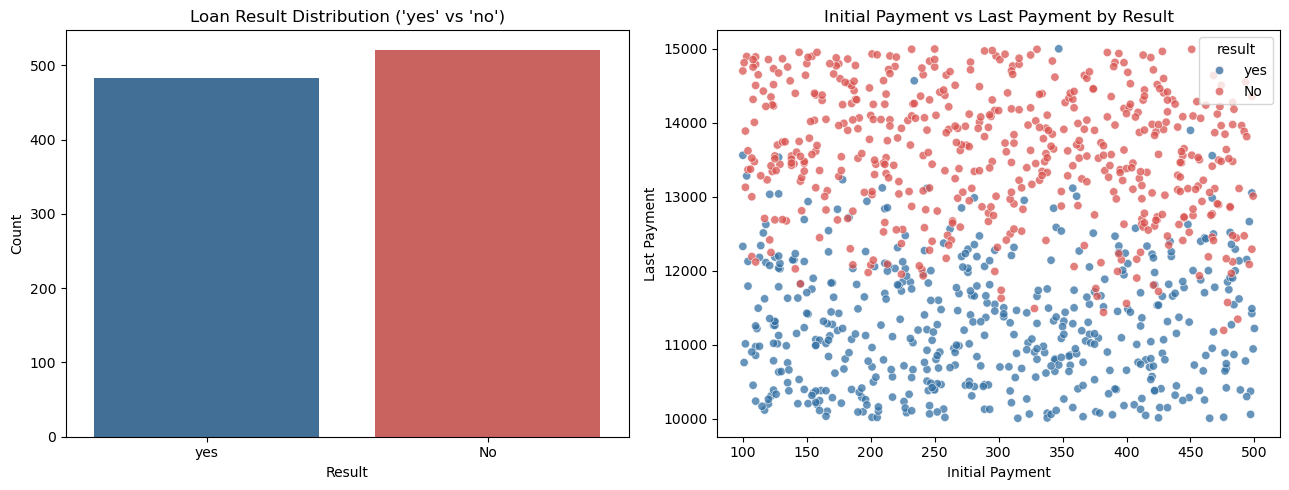

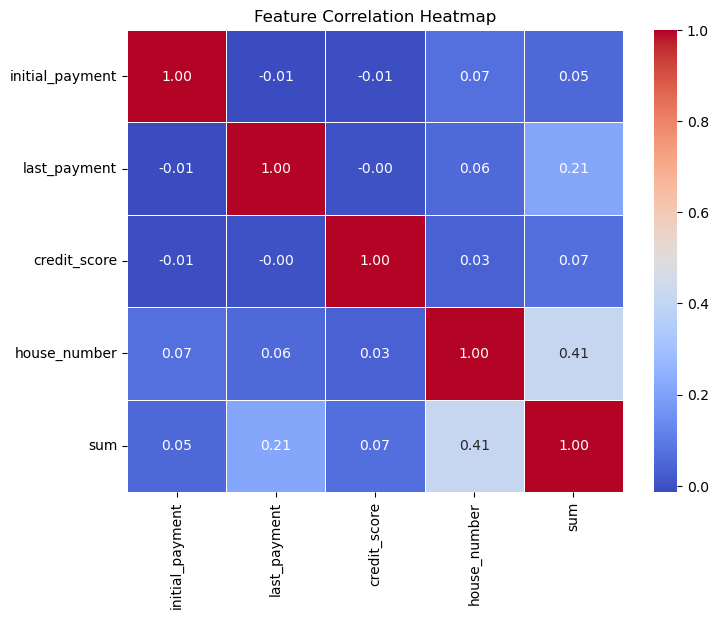

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Chart 1: Target Variable Distribution
sns.countplot(x='result', data=df, hue='result', palette=['#3470a3', '#d9534f'], legend=False, ax=axes[0])
axes[0].set_title("Loan Result Distribution ('yes' vs 'no')")
axes[0].set_xlabel('Result')
axes[0].set_ylabel('Count')

# Chart 2: Initial Payment vs Last Payment by Result
sns.scatterplot(x='initial_payment', y='last_payment', hue='result', data=df, palette=['#3470a3', '#d9534f'], alpha=0.75, ax=axes[1])
axes[1].set_title('Initial Payment vs Last Payment by Result')
axes[1].set_xlabel('Initial Payment')
axes[1].set_ylabel('Last Payment')

plt.tight_layout()
plt.show()

# Chart 3: Feature Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.show()

In [7]:
# Check and remove any duplicate rows if present
df = df.drop_duplicates()

# Separate Features (X) and Target (y)
X = df.drop(columns=['result'])
y = df['result']

# Encode target labels ('no' -> 0, 'yes' -> 1)
le = LabelEncoder()
y_encoded = le.fit_transform(y)
print("Target classes mapping:", dict(zip(le.classes_, le.transform(le.classes_))))

# 80/20 Train-Test Split with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.20, random_state=42, stratify=y_encoded
)

# Normalize/Standardize numerical features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train shape:", X_train_scaled.shape)
print("X_test shape :", X_test_scaled.shape)

Target classes mapping: {'No': 0, 'yes': 1}
X_train shape: (803, 5)
X_test shape : (201, 5)


Decision Tree model successfully trained.


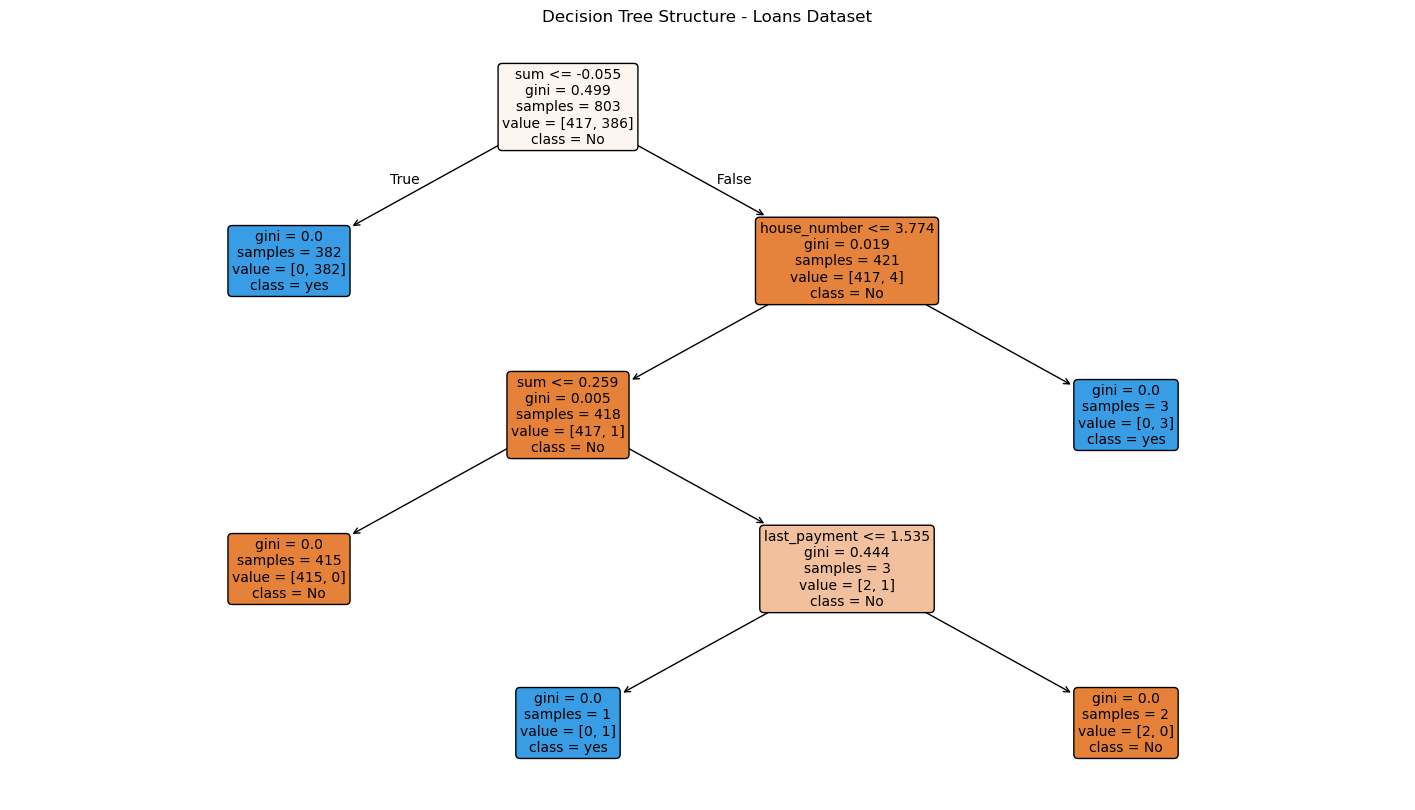

In [8]:
# Initialize and train the Decision Tree Classifier
dt_model = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42)
dt_model.fit(X_train_scaled, y_train)

# Predict on test set
y_pred = dt_model.predict(X_test_scaled)

print("Decision Tree model successfully trained.")

# Visualize the trained Decision Tree
plt.figure(figsize=(18, 10))
plot_tree(
    dt_model,
    feature_names=X.columns.tolist(),
    class_names=le.classes_.tolist(),
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Structure - Loans Dataset")
plt.show()

Accuracy : 1.0000 (100.00%)
Precision: 1.0000
Recall   : 1.0000
F1-Score : 1.0000

--- Classification Report ---
              precision    recall  f1-score   support

          No       1.00      1.00      1.00       104
         yes       1.00      1.00      1.00        97

    accuracy                           1.00       201
   macro avg       1.00      1.00      1.00       201
weighted avg       1.00      1.00      1.00       201



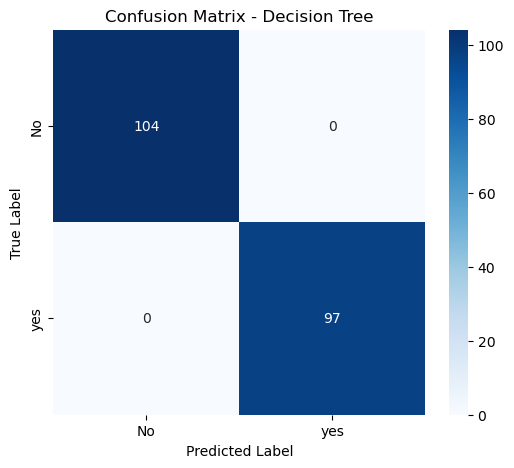

In [9]:
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy : {acc:.4f} ({acc*100:.2f}%)")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-Score : {f1:.4f}")

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_,
            yticklabels=le.classes_)
plt.title('Confusion Matrix - Decision Tree')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()